## Imports

In [78]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder, OrdinalEncoder

## Read Dataset

In [38]:
df = pd.read_csv('Lab 2-17.7.2026/fishdata.csv')
print(df.head())

print('\n')

fish_cols = ['Species', 'Weight', 'Length1', 'Length2', 'Length3', 'Height', 'Width']
df = pd.read_csv('Lab 2-17.7.2026/fishdata.csv', names=fish_cols)
print(df.head())

   Bream  242.0  23.2  25.4  30.0    11.52    4.02
0  Bream  290.0  24.0  26.3  31.2  12.4800  4.3056
1  Bream  340.0  23.9  26.5  31.1  12.3778  4.6961
2  Bream  363.0  26.3  29.0  33.5  12.7300  4.4555
3  Bream  430.0  26.5  29.0  34.0  12.4440  5.1340
4  Bream  450.0  26.8  29.7  34.7  13.6024  4.9274


  Species  Weight  Length1  Length2  Length3   Height   Width
0   Bream   242.0     23.2     25.4     30.0  11.5200  4.0200
1   Bream   290.0     24.0     26.3     31.2  12.4800  4.3056
2   Bream   340.0     23.9     26.5     31.1  12.3778  4.6961
3   Bream   363.0     26.3     29.0     33.5  12.7300  4.4555
4   Bream   430.0     26.5     29.0     34.0  12.4440  5.1340


## EDA

In [64]:
df['Species'].value_counts()

Species
Perch        56
Bream        35
Roach        20
Pike         17
Smelt        14
Parkki       11
Whitefish     6
Name: count, dtype: int64

In [39]:
df.iloc[-1].value_counts()

158
Smelt     1
19.9      1
13.8      1
15.0      1
16.2      1
2.9322    1
1.8792    1
Name: count, dtype: int64

In [40]:
df['Weight'].value_counts()

Weight
300.0     6
1000.0    5
500.0     5
120.0     5
700.0     5
         ..
60.0      1
55.0      1
800.0     1
306.0     1
19.9      1
Name: count, Length: 101, dtype: int64

In [41]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 159 entries, 0 to 158
Data columns (total 7 columns):
 #   Column   Non-Null Count  Dtype  
---  ------   --------------  -----  
 0   Species  159 non-null    object 
 1   Weight   159 non-null    float64
 2   Length1  159 non-null    float64
 3   Length2  159 non-null    float64
 4   Length3  159 non-null    float64
 5   Height   159 non-null    float64
 6   Width    159 non-null    float64
dtypes: float64(6), object(1)
memory usage: 8.8+ KB


In [42]:
df.describe()

,Weight,Length1,Length2,Length3,Height,Width
count,159.000000,159.000000,159.000000,159.000000,159.000000,159.000000
mean,398.326415,26.247170,28.415723,31.227044,8.970994,4.417486
std,357.978317,9.996441,10.716328,11.610246,4.286208,1.685804
min,0.000000,7.500000,8.400000,8.800000,1.728400,1.047600
25%,120.000000,19.050000,21.000000,23.150000,5.944800,3.385650
50%,273.000000,25.200000,27.300000,29.400000,7.786000,4.248500
75%,650.000000,32.700000,35.500000,39.650000,12.365900,5.584500
max,1650.000000,59.000000,63.400000,68.000000,18.957000,8.142000


In [43]:
df.isnull().sum()

Species    0
Weight     0
Length1    0
Length2    0
Length3    0
Height     0
Width      0
dtype: int64

## Missing Values

In [44]:
from sklearn.impute import SimpleImputer

In [45]:
num_cols = df.select_dtypes(include=['float64']).columns
cat_cols = df.select_dtypes(include=['object', 'category']).columns

In [46]:
num_imputer = SimpleImputer(strategy='mean')
df[num_cols] = num_imputer.fit_transform(df[num_cols])

cat_imputer = SimpleImputer(strategy='most_frequent')
df[cat_cols] = cat_imputer.fit_transform(df[cat_cols])

## Split Dataset

In [66]:
df_reg = df[['Weight', 'Length1', 'Length2', 'Length3', 'Height', 'Width']]

In [67]:
X = df_reg.drop(columns='Weight')
y = df_reg['Weight']

y_class = df['Species']

In [68]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=1265
)

X_class_train, X_class_test, y_class_train, y_class_test = train_test_split(
    X, y_class, test_size=0.2, random_state=1265
)

## Standardisation

In [69]:
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

X_class_train_scaled = scaler.fit_transform(X_class_train)
X_class_test_scaled = scaler.transform(X_class_test)

## Model

### Regression

#### Linear

In [70]:
from sklearn.linear_model import LinearRegression

lin_model = LinearRegression()
lin_model.fit(X_train_scaled, y_train)
y_pred = lin_model.predict(X_test_scaled)

In [71]:
# Accuracy metrics
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

mae = mean_absolute_error(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
r2 = r2_score(y_test, y_pred)

print(mae)
print(mse)
print(r2)

105.21496883103308
15294.34908291687
0.8894282882910205


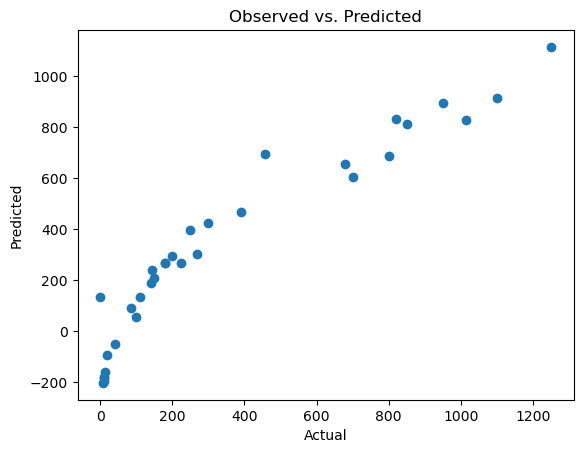

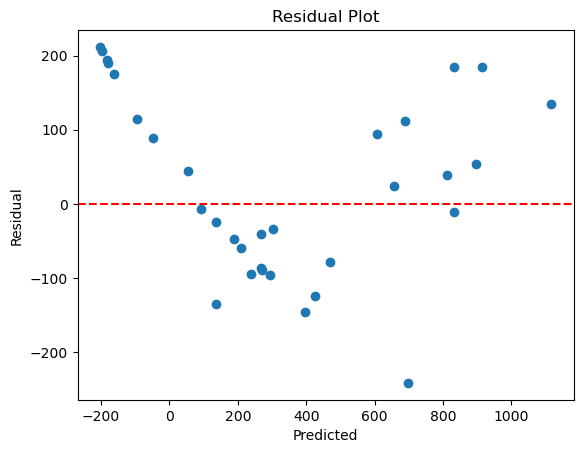

In [86]:
# Plot

plt.scatter(y_test, y_pred)
plt.xlabel('Actual')
plt.ylabel('Predicted')
plt.title('Observed vs. Predicted')
plt.show()

residuals = y_test - y_pred
plt.scatter(y_pred, residuals)
plt.axhline(0, color='red', linestyle='--')
plt.xlabel('Predicted')
plt.ylabel('Residual')
plt.title('Residual Plot')
plt.show()

#### KNN

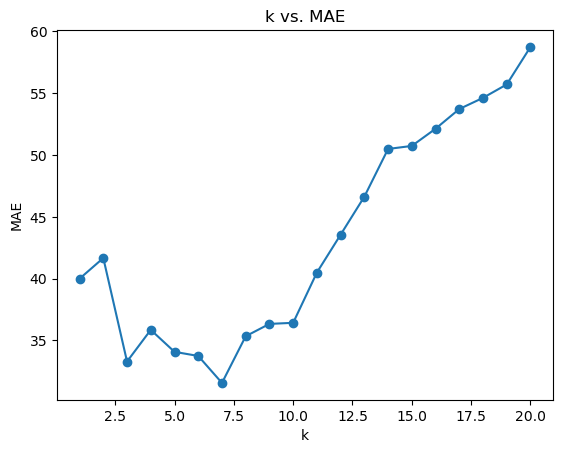

Besk k:  7


In [99]:
from sklearn.neighbors import KNeighborsRegressor

k_vals = range(1, 21)
mae_scores = []
for k in k_vals:
    knn = KNeighborsRegressor(n_neighbors=k)
    knn.fit(X_train_scaled, y_train)
    mae_scores.append(mean_absolute_error(y_test, knn.predict(X_test_scaled)))

best_k = list(k_vals)[int(np.argmin(mae_scores))]
plt.plot(list(k_vals), mae_scores, marker='o')
plt.xlabel('k')
plt.ylabel('MAE')
plt.title('k vs. MAE')
plt.show()

print("Besk k: ", best_k)

In [100]:
knn_reg = KNeighborsRegressor(n_neighbors=best_k)
knn.fit(X_train_scaled, y_train)
y_pred = knn.predict(X_test_scaled)

In [101]:
# Accuracy metrics
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

mae = mean_absolute_error(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
r2 = r2_score(y_test, y_pred)

print(mae)
print(mse)
print(r2)

58.73171875
8844.84197265625
0.936055512306542


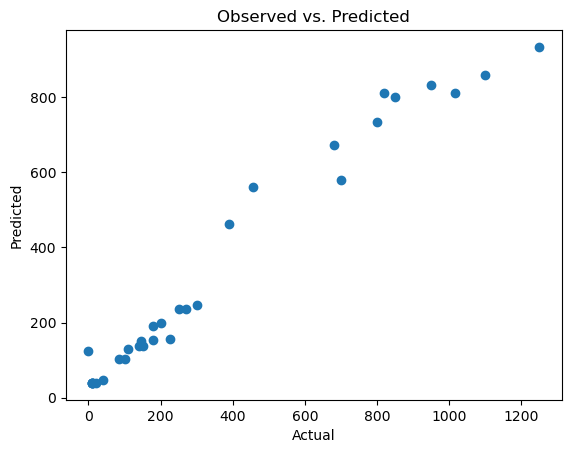

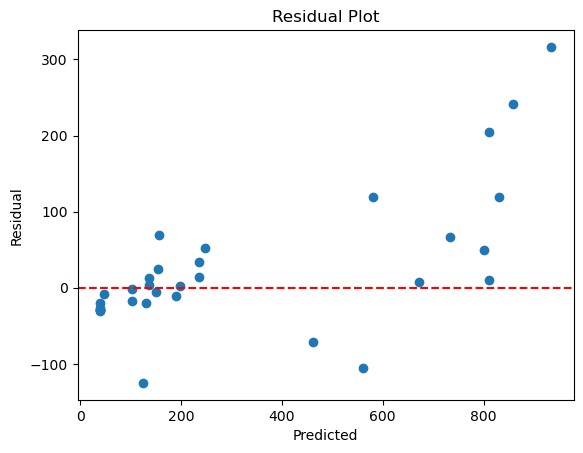

In [102]:
# Plot

plt.scatter(y_test, y_pred)
plt.xlabel('Actual')
plt.ylabel('Predicted')
plt.title('Observed vs. Predicted')
plt.show()

residuals = y_test - y_pred
plt.scatter(y_pred, residuals)
plt.axhline(0, color='red', linestyle='--')
plt.xlabel('Predicted')
plt.ylabel('Residual')
plt.title('Residual Plot')
plt.show()

### Classification

In [73]:
from sklearn.linear_model import LogisticRegression

log_model = LogisticRegression(max_iter=1000, random_state=1265)
log_model.fit(X_class_train_scaled, y_class_train)
y_class_pred = log_model.predict(X_class_test_scaled)

In [77]:
# Acccuracy metrics
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    confusion_matrix,
    classification_report
)

accuracy = accuracy_score(y_class_test, y_class_pred)
f1 = f1_score(y_class_test, y_class_pred, average='weighted') # multi-class

print(accuracy)
print(f1)

print('\n')
print(classification_report(y_class_test, y_class_pred))

0.875
0.8203125


              precision    recall  f1-score   support

       Bream       1.00      1.00      1.00         4
      Parkki       1.00      1.00      1.00         2
       Perch       0.78      1.00      0.88        14
        Pike       1.00      1.00      1.00         2
       Roach       0.00      0.00      0.00         2
       Smelt       1.00      1.00      1.00         6
   Whitefish       0.00      0.00      0.00         2

    accuracy                           0.88        32
   macro avg       0.68      0.71      0.70        32
weighted avg       0.78      0.88      0.82        32



/opt/anaconda3/lib/python3.12/site-packages/sklearn/metrics/_classification.py:1531: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/opt/anaconda3/lib/python3.12/site-packages/sklearn/metrics/_classification.py:1531: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/opt/anaconda3/lib/python3.12/site-packages/sklearn/metrics/_classification.py:1531: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


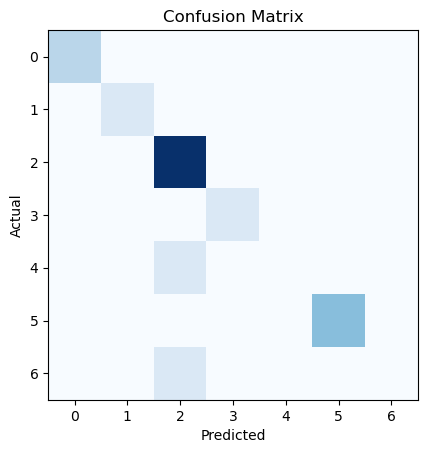

In [90]:
# Plot

cm = confusion_matrix(y_class_test, y_class_pred, labels=log_model.classes_)
plt.imshow(cm, cmap='Blues')
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title('Confusion Matrix')
plt.show()

#### KNN

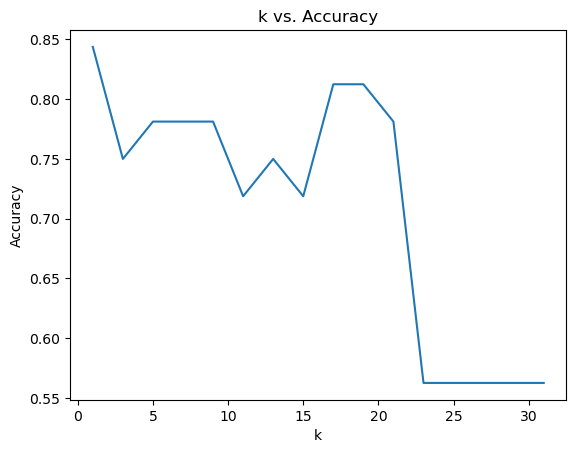

Best k:  1


In [110]:
from sklearn.neighbors import KNeighborsClassifier

k_values = range(1, 32, 2)
accuracies = []
for k in k_values:
    knn = KNeighborsClassifier(n_neighbors=k)
    knn.fit(X_class_train_scaled, y_class_train)
    accuracies.append(accuracy_score(y_class_test, knn.predict(X_class_test_scaled)))

best_k = list(k_values)[int(np.argmax(accuracies))]
plt.plot(list(k_values), accuracies)
plt.xlabel('k')
plt.ylabel('Accuracy')
plt.title('k vs. Accuracy')
plt.show()

print("Best k: ", best_k)

In [111]:
knn_class = KNeighborsClassifier(n_neighbors=best_k)
knn_class.fit(X_class_train_scaled, y_class_train)
y_class_pred = knn_class.predict(X_class_test_scaled)

In [112]:
# Acccuracy metrics
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    confusion_matrix,
    classification_report
)

accuracy = accuracy_score(y_class_test, y_class_pred)
f1 = f1_score(y_class_test, y_class_pred, average='weighted') # multi-class

print(accuracy)
print(f1)

print('\n')
print(classification_report(y_class_test, y_class_pred))

0.84375
0.8604166666666667


              precision    recall  f1-score   support

       Bream       1.00      1.00      1.00         4
      Parkki       1.00      1.00      1.00         2
       Perch       0.91      0.71      0.80        14
        Pike       1.00      1.00      1.00         2
       Roach       0.33      1.00      0.50         2
       Smelt       1.00      1.00      1.00         6
   Whitefish       1.00      0.50      0.67         2

    accuracy                           0.84        32
   macro avg       0.89      0.89      0.85        32
weighted avg       0.92      0.84      0.86        32



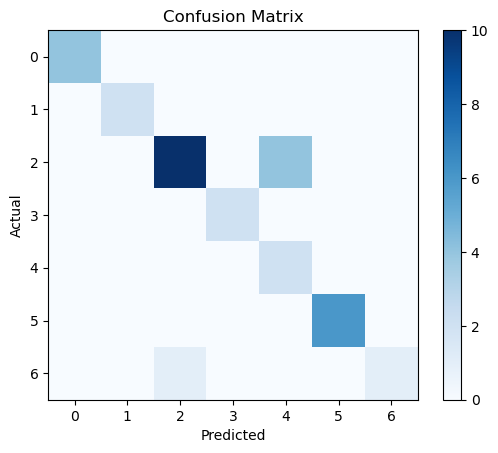

In [114]:
# Plot

cm = confusion_matrix(y_class_test, y_class_pred, labels=knn_class.classes_)
plt.imshow(cm, cmap='Blues')
plt.colorbar()
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title('Confusion Matrix')
plt.show()